# 02 · Ingeniería de características — SportSmart Perú

Fase CRISP-DM: **Preparación de los datos**. Cubre las secciones 14 y 15 de la propuesta: construcción de variables, integración, formateo, colinealidad, selección, reducción de dimensionalidad, codificación, escalamiento, valores atípicos y balanceo.

La selección y el balanceo se demuestran con el dataset de abandono porque requieren una variable objetivo. El modelo definitivo de abandono corresponde a la semana 16.

In [1]:
import sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().resolve().parents[1]
sys.path.insert(0, str(ROOT))
warnings.filterwarnings('ignore')
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from src.config import PROCESSED, REPORTS
from src.features import seleccion, variables
from src.data.estilo_graficos import AZUL, GRIS, NARANJA, SUPERFICIE, TINTA, TENUE, aplicar_estilo, barras_h, guardar, numero
aplicar_estilo()
salida = variables.main()
res = seleccion.main()
cli, ab, prod = salida['clientes_variables'], salida['abandono_dataset'], salida['productos_abc_xyz']

clientes_variables     (7812, 51)
abandono_dataset       (2529, 44)
productos_abc_xyz      (321, 12)
serie_diaria           (1369, 6)
panel_producto_mes     (14445, 23)


## 1. Variables construidas

| Tabla en `data/processed` | Una fila representa | Uso |
|---|---|---|
| `clientes_variables` | Comprador al cierre | Clustering, RFM, LRFM y CLV |
| `abandono_dataset` | Comprador activo al corte de abr-2026 | Selección de variables y clasificación |
| `productos_abc_xyz` | Producto | Clasificación ABC/XYZ |
| `serie_diaria` | Día | Series de tiempo |
| `panel_producto_mes` | Producto y mes | Regresión |

Las variables de cliente integran pedidos, productos, logística, devoluciones, atención, opiniones, marketing y navegación, usando solo hechos anteriores a la fecha de corte. El CLV se estima como margen anual × r ÷ (1 + d − r), con la retención anual observada (r) y una tasa de descuento supuesta de 10 % (d).

In [2]:
cli[['recencia', 'frecuencia', 'monetario', 'longitud', 'margen_anual', 'clv', 'rfm_total', 'lrfm_total']].describe().T[['mean', '50%', 'max']].round(1)

,mean,50%,max
recencia,523.1,461.0,1367.0
frecuencia,7.7,4.0,267.0
monetario,1790.6,804.1,62064.8
longitud,225.9,132.0,1365.0
margen_anual,381.4,178.4,8977.9
clv,275.2,128.7,6477.3
rfm_total,9.0,9.0,15.0
lrfm_total,12.0,12.0,20.0


## 2. Clasificación ABC/XYZ

ABC ordena por ingresos acumulados (80 % y 95 %). XYZ mide la variabilidad de las unidades mensuales: X hasta 0,5 de coeficiente de variación, Y hasta 1 y Z por encima.

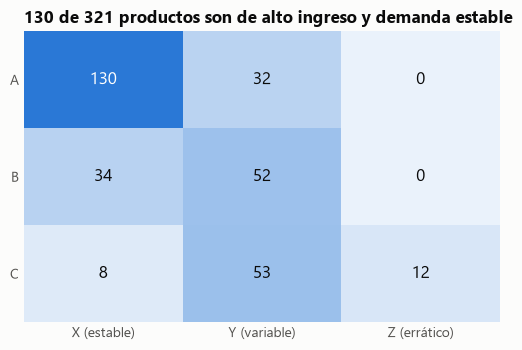

Ingresos por clase (%): {'A': 79.8, 'B': 15.2, 'C': 5.0}


In [3]:
m = pd.DataFrame(res['abc_xyz']['matriz']).T.reindex(index=list('ABC'), columns=list('XYZ'))
fig, ax = plt.subplots(figsize=(5.2, 3.6)); ax.grid(False); [s.set_visible(False) for s in ax.spines.values()]
ax.imshow(m.values, cmap=LinearSegmentedColormap.from_list('az', ['#eaf2fb', AZUL]), aspect='auto')
ax.set_xticks(range(3), ['X (estable)', 'Y (variable)', 'Z (errático)']); ax.set_yticks(range(3), ['A', 'B', 'C'])
for i in range(3):
    for j in range(3):
        v = m.iat[i, j]; ax.text(j, i, str(v), ha='center', va='center', fontsize=12, color='white' if v > 70 else TINTA)
ax.set_title(f"{m.loc['A', 'X']} de 321 productos son de alto ingreso y demanda estable")
guardar(fig, 'abc_xyz')
print('Ingresos por clase (%):', res['abc_xyz']['ingresos_pct_abc'])

## 3. Codificación, escalamiento y valores atípicos

One-Hot para categorías sin orden y Label Encoding para la clase ABC, que sí tiene orden. StandardScaler se usará en clustering y modelos lineales; MinMaxScaler es la alternativa cuando se requiere un rango de 0 a 1.

In [4]:
print('Categorías por variable con One-Hot:', res['codificacion']['one_hot'], '-> columnas:', res['codificacion']['columnas_tras_one_hot'])
print('Label Encoding de ABC:', res['codificacion']['label_encoding_abc'])
display(pd.DataFrame(res['escalamiento']).T)
pd.DataFrame(res['atipicos']).T

Categorías por variable con One-Hot: {'genero': 3, 'zona': 2, 'canal_adquisicion': 5, 'deporte_preferido': 6} -> columnas: 51
Label Encoding de ABC: {'A': 0, 'B': 1, 'C': 2}


,original_max,standard_media,standard_desv,minmax_min,minmax_max
recencia,1367.00,0.0,1.0,0.0,1.0
frecuencia,267.00,0.0,1.0,0.0,1.0
monetario,62064.75,0.0,1.0,0.0,1.0


,iqr,z3,asimetria,asimetria_log
recencia,0.0,0.0,0.39,-1.42
frecuencia,704.0,155.0,5.19,0.78
monetario,706.0,161.0,5.15,-0.07
ticket_medio,304.0,127.0,1.25,-0.68


Los compradores atípicos por IQR o Z-Score son clientes de gran valor, no errores, por lo que se conservan. La transformación logarítmica reduce la asimetría de frecuencia y monto de más de 5 a menos de 1.

## 4. Eliminación de colinealidad

Con correlación de Spearman mayor a 0,85 se retira la variable menos asociada con el objetivo. Se calcula solo con entrenamiento.

In [5]:
col = res['colinealidad']
print('Columnas:', col['columnas_antes'], '->', col['columnas_despues'], '| VIF máximo antes:', numero(col['vif_max_antes'], 2), '| VIF máximo después:', numero(max(col['vif_despues'].values()), 2))
pd.DataFrame(col['retiradas'])

Columnas: 51 -> 36 | VIF máximo antes: 1 029,97 | VIF máximo después: 10,05


,retirada,conservada,rho
0,minutos_totales,sesiones,1.000
1,paginas_vistas,sesiones,1.000
2,margen_total,monetario,0.998
3,sesiones,tiene_navegacion,0.988
4,items,monetario,0.977
5,descuento_medio,pct_con_campania,0.961
6,carritos_abandonados,tiene_navegacion,0.952
7,genero_M,genero_F,0.946
8,monetario,frecuencia,0.943
9,frecuencia,frecuencia_365d,0.936


## 5. Selección por importancia

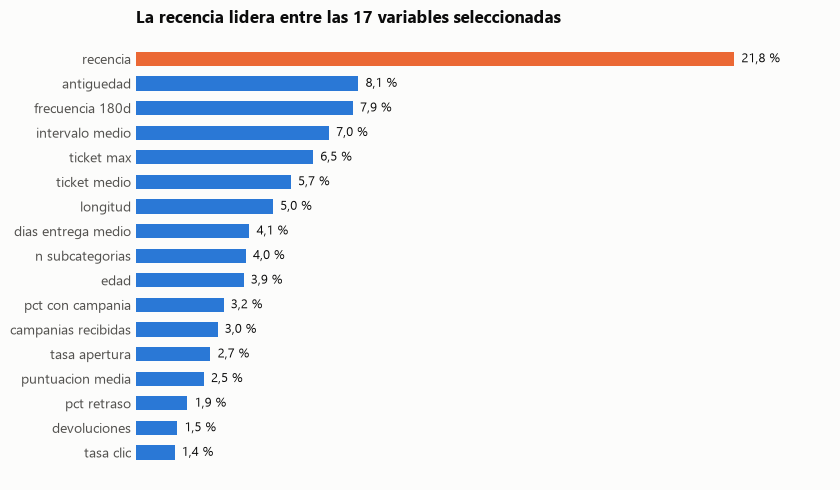

,auc,recall
Todas,0.784,0.767
Sin colinealidad,0.791,0.767
Seleccionadas,0.787,0.753


In [6]:
imp = res['importancia']; ser = pd.Series(imp['importancias'])[imp['seleccionadas']]
fig, ax = plt.subplots(figsize=(8.5, 5))
barras_h(ax, [s.replace('_', ' ') for s in ser.index], list(ser.values * 100), [NARANJA] + [AZUL] * (len(ser) - 1), lambda v: numero(v) + ' %')
ax.set_title(f"La recencia lidera entre las {imp['n_seleccionadas']} variables seleccionadas")
guardar(fig, 'importancia_variables')
pd.DataFrame(res['comparacion_variables']).T

## 6. Reducción de dimensionalidad

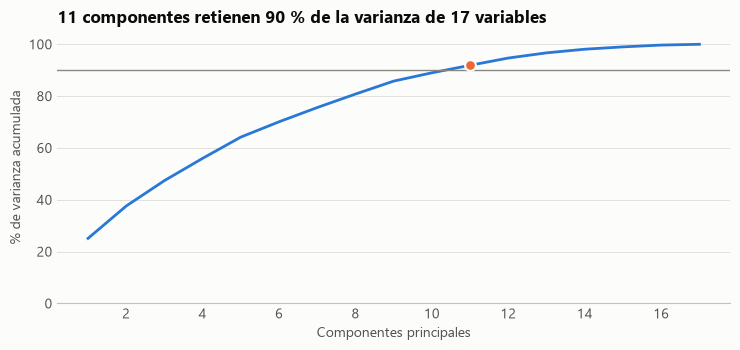

,auc,recall
Logística con variables seleccionadas,0.774,0.682
Logística con PCA (90 %),0.775,0.679
LDA,0.775,0.679
QDA,0.756,0.622


In [7]:
red = res['reduccion']; ac = [v * 100 for v in red['pca_varianza_acumulada']]; x = list(range(1, len(ac) + 1))
fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.plot(x, ac, color=AZUL, lw=2); ax.axhline(90, color=TENUE, lw=1)
n = red['pca_componentes_90']; ax.scatter([n], [ac[n - 1]], s=60, color=NARANJA, edgecolor=SUPERFICIE, linewidth=1.5, zorder=3)
ax.set_ylim(0, 105); ax.set_xlabel('Componentes principales'); ax.set_ylabel('% de varianza acumulada')
ax.set_title(f"{n} componentes retienen 90 % de la varianza de {red['n_variables']} variables")
guardar(fig, 'pca_varianza')
pd.DataFrame(red['modelos']).T

## 7. Balanceo

Se aplica solo a entrenamiento. Prueba con regresión logística.

In [8]:
print(res['abandono'])
pd.DataFrame(res['balanceo']).T

{'filas': 2529, 'tasa_abandono_pct': 46.8, 'permanece': 1345, 'abandona': 1184, 'entrenamiento': 1896, 'prueba': 633}


,permanece,abandona,auc,recall,no_aplica
Sin balanceo,1008.0,888.0,0.774,0.682,NaN
Undersampling,888.0,888.0,0.775,0.713,NaN
Oversampling,1008.0,1008.0,0.773,0.73,NaN
SMOTE,1008.0,1008.0,0.774,0.713,NaN
ADASYN,NaN,NaN,NaN,NaN,No samples will be generated with the provided...


## 8. Conclusiones

- Se construyeron variables de cliente, producto, día y producto-mes. La serie diaria y el panel cuadran con las ventas válidas (S/ 13 988 027,87), y una prueba automática confirma que no hay fuga de información.
- La eliminación de colinealidad reduce las columnas de 51 a 36 y el VIF máximo de 1 029,97 a 10,05, sin perder capacidad predictiva (AUC de 0,784 a 0,791). Tras ella, longitud queda levemente sobre 10.
- La selección por importancia deja 17 variables con AUC de 0,787, casi igual al modelo completo. Se prefiere por ser más simple.
- PCA necesita 11 componentes para 90 % de varianza y no mejora el AUC (0,775 frente a 0,774), por lo que no aporta frente a las 17 variables interpretables. LDA iguala a la regresión logística (0,775) y QDA queda por debajo (0,756).
- El abandono **casi no está desbalanceado** (46,8 %). Las técnicas de balanceo no cambian el AUC y solo mueven el recall de 0,682 a un máximo de 0,730; ADASYN no genera muestras porque las clases están casi equilibradas. Oversampling o un ajuste de umbral pueden evaluarse en la semana 16.
- En ABC/XYZ, 162 productos (A) concentran 79,8 % de los ingresos: la concentración es moderada, porque son la mitad del catálogo.

Estos valores de AUC son una demostración; el modelo de abandono se desarrolla y valida en la semana 16.